# 03. Decision tree regression

We predict the final numerical grade (`course_numeric_grade`) from Moodle activity during the first 8 weeks of the semester. The model is a regression tree (`DecisionTreeRegressor`). It is trained on the earlier years and tested separately on 2025 and 2026, using exactly the same prepared dataset and the same four predictors as the other models in the team.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

## 1. Load the shared train/test split

`shared_train.csv` contains the earlier years and `shared_test.csv` contains 2025 and 2026. The split is fixed in advance, so the test years are never used for training or for choosing the tree depth.

In [2]:
train = pd.read_csv("shared_train.csv")
test = pd.read_csv("shared_test.csv")

print("train:", train.shape, " test:", test.shape)
print("train years:", sorted(train["year"].unique()))
print("test years:", sorted(test["year"].unique()))
train.head()

train: (551, 7)  test: (279, 7)
train years: [2019, 2021, 2022, 2023, 2024]
test years: [2025, 2026]


,year,actor_id,course_numeric_grade,total_events,active_days,course_module_views,course_views
0,2019,S027cf9,72.10,132,18,20,34
1,2019,S032255,67.70,48,6,18,8
2,2019,S03a8b8,107.02,221,30,39,75
3,2019,S04cf7f,85.85,161,20,26,38
4,2019,S05f285,37.15,456,32,76,177


## 2. Predictors and target

We use the four shared Moodle activity variables and the final grade as the target.

In [3]:
FEATURES = ["total_events", "active_days", "course_module_views", "course_views"]
TARGET = "course_numeric_grade"

X_train = train[FEATURES]
y_train = train[TARGET]

X_test_2025 = test.loc[test["year"] == 2025, FEATURES]
y_test_2025 = test.loc[test["year"] == 2025, TARGET]
X_test_2026 = test.loc[test["year"] == 2026, FEATURES]
y_test_2026 = test.loc[test["year"] == 2026, TARGET]

print(len(X_train), len(X_test_2025), len(X_test_2026))

551 137 142


## 3. A decision tree and the danger of overfitting

A regression tree splits the students into groups by asking yes/no questions about the predictors (for example "was `active_days` at most 17.5?"). The prediction in each final group (leaf) is the average grade of the training students in that leaf.

A tree can always become deeper. An unlimited tree can put every training student in its own leaf and reach a training error of almost zero, but such a tree only memorises the training data. We therefore control the size of the tree with `max_depth` and choose it using only the training years.

For validation we use "leave one year out" cross-validation: the tree is trained on four of the five training years and validated on the fifth. The test years 2025 and 2026 are not touched. This is the same validation scheme that the other team members use, so the results are comparable.

In [4]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, None]

grid = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid={"max_depth": depths},
    cv=LeaveOneGroupOut(),
    scoring="neg_mean_absolute_error",
)
grid.fit(X_train, y_train, groups=train["year"])

depth_table = pd.DataFrame({
    "max_depth": ["unlimited" if d is None else d for d in depths],
    "cv_MAE": -grid.cv_results_["mean_test_score"],
})

# Training error of the same depths, to show the overfitting gap.
depth_table["train_MAE"] = [
    mean_absolute_error(
        y_train,
        DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE)
        .fit(X_train, y_train)
        .predict(X_train),
    )
    for d in depths
]
depth_table = depth_table.round(2)

best_depth = grid.best_params_["max_depth"]
print("best max_depth:", best_depth)
depth_table

best max_depth: 2


,max_depth,cv_MAE,train_MAE
0,1,19.16,17.48
1,2,18.65,17.11
2,3,19.17,16.63
3,4,19.93,15.97
4,5,20.17,14.79
5,6,20.73,13.83
6,8,21.49,11.59
7,10,22.98,7.96
8,unlimited,25.07,0.00


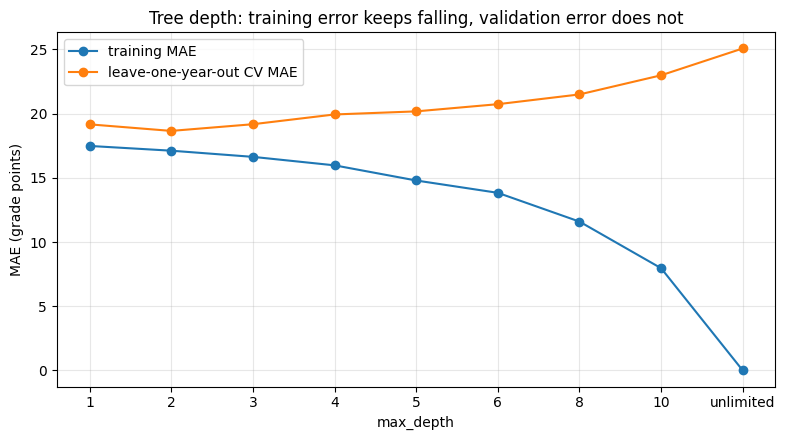

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))

positions = range(len(depths))
ax.plot(positions, depth_table["train_MAE"], marker="o", label="training MAE")
ax.plot(positions, depth_table["cv_MAE"], marker="o", label="leave-one-year-out CV MAE")

ax.set_xticks(list(positions))
ax.set_xticklabels(depth_table["max_depth"])
ax.set_xlabel("max_depth")
ax.set_ylabel("MAE (grade points)")
ax.set_title("Tree depth: training error keeps falling, validation error does not")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig("decision_tree_depth_tuning.png", dpi=150)
plt.show()
depth_table.to_csv("decision_tree_depth_tuning.csv", index=False)

## 4. Final model with the selected depth

We refit the tree on all five training years with the depth chosen above.

In [6]:
final_tree = DecisionTreeRegressor(max_depth=best_depth, random_state=RANDOM_STATE)
final_tree.fit(X_train, y_train)

print("depth:", final_tree.get_depth())
print("leaves:", final_tree.get_n_leaves())
print("training MAE:", round(mean_absolute_error(y_train, final_tree.predict(X_train)), 2))

importance = pd.Series(final_tree.feature_importances_, index=FEATURES).sort_values(ascending=False)
importance.round(3)

depth: 2
leaves: 4
training MAE: 17.11


active_days            0.806
total_events           0.194
course_module_views    0.000
course_views           0.000
dtype: float64

## 5. Predictions for 2025 and 2026 separately

In [7]:
pred_2025 = final_tree.predict(X_test_2025)
pred_2026 = final_tree.predict(X_test_2026)

print("2025:", np.round(pred_2025[:5], 1))
print("2026:", np.round(pred_2026[:5], 1))

2025: [76.4 76.4 76.4 57.7 36.5]
2026: [36.5 36.5 36.5 36.5 66.5]


## 6. MAE, baseline comparison and other metrics

MAE (mean absolute error) is the average distance between the real and the predicted grade, in grade points. The baseline always predicts the average grade of the training years. We also report RMSE (which punishes large mistakes more strongly) and R² (the share of the grade variance explained).

In [8]:
baseline_value = y_train.mean()

rows = []
for year, y_true, y_pred in [
    (2025, y_test_2025, pred_2025),
    (2026, y_test_2026, pred_2026),
]:
    rows.append({
        "year": year,
        "students": len(y_true),
        "MAE_tree": mean_absolute_error(y_true, y_pred),
        "MAE_baseline": mean_absolute_error(y_true, np.full(len(y_true), baseline_value)),
        "RMSE_tree": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2_tree": r2_score(y_true, y_pred),
    })

results = pd.DataFrame(rows).round(2)
results["improvement"] = (results["MAE_baseline"] - results["MAE_tree"]).round(2)

print("baseline (mean training grade):", round(baseline_value, 2))
results.to_csv("decision_tree_results.csv", index=False)
results

baseline (mean training grade): 66.93


,year,students,MAE_tree,MAE_baseline,RMSE_tree,R2_tree,improvement
0,2025,137,19.65,20.21,25.04,0.05,0.56
1,2026,142,21.64,21.02,25.32,0.13,-0.62


## 7. Actual versus predicted grades

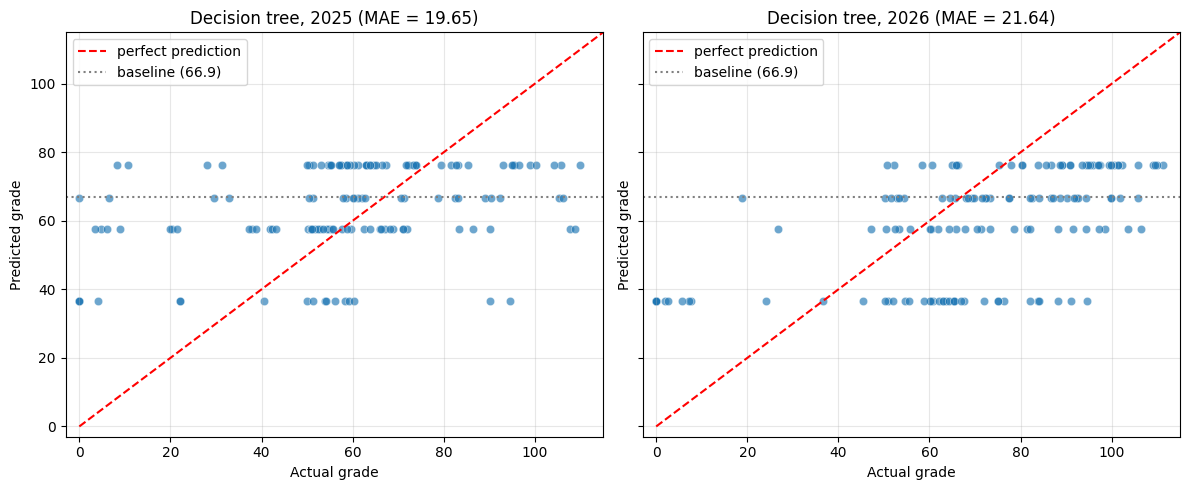

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for ax, year, y_true, y_pred in [
    (axes[0], 2025, y_test_2025, pred_2025),
    (axes[1], 2026, y_test_2026, pred_2026),
]:
    ax.scatter(y_true, y_pred, alpha=0.65, edgecolor="white", linewidth=0.4)
    ax.plot([0, 115], [0, 115], color="red", linestyle="--", label="perfect prediction")
    ax.axhline(baseline_value, color="grey", linestyle=":", label=f"baseline ({baseline_value:.1f})")
    ax.set_title(f"Decision tree, {year} (MAE = {mean_absolute_error(y_true, y_pred):.2f})")
    ax.set_xlabel("Actual grade")
    ax.set_ylabel("Predicted grade")
    ax.set_xlim(-3, 115)
    ax.set_ylim(-3, 115)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig("decision_tree_predictions.png", dpi=150)
plt.show()

## 8. The tree and its feature importance

The tree is small enough to draw completely. The colour shows the predicted grade in each leaf, and the values under each node are the number of training students and their average grade.

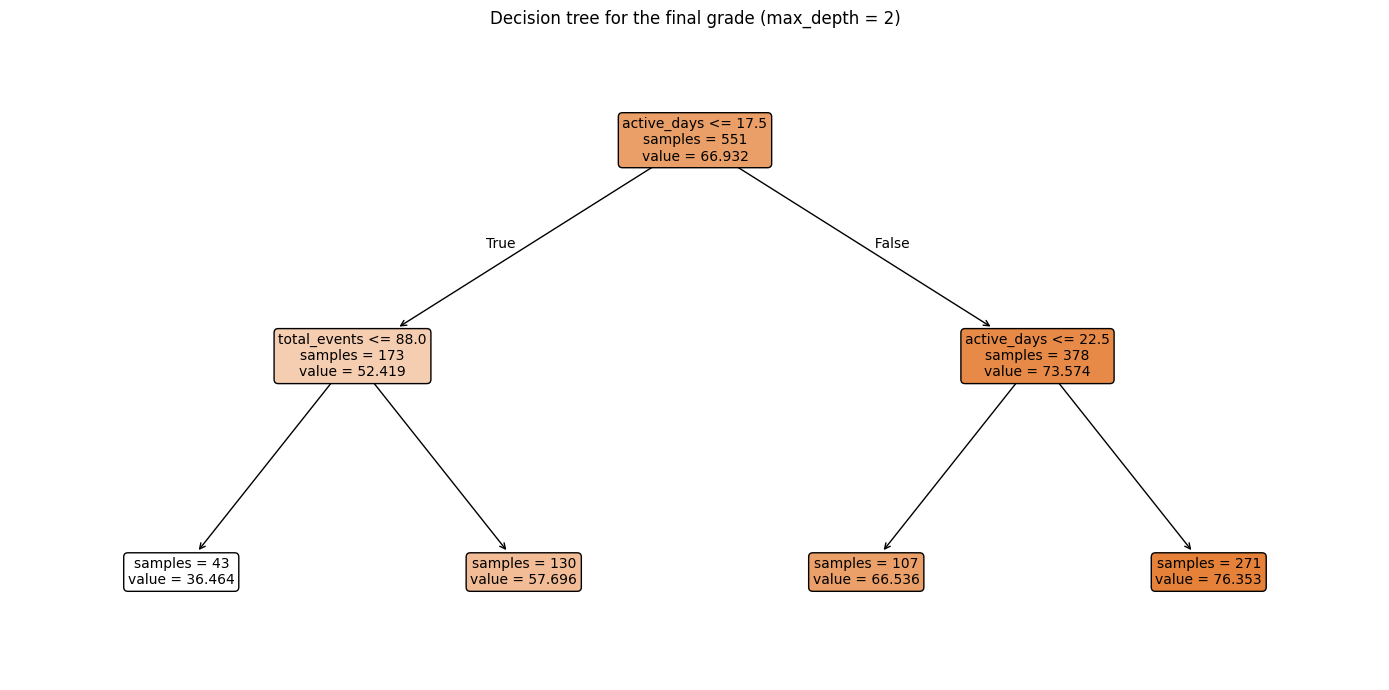

In [10]:
fig, ax = plt.subplots(figsize=(14, 7))

plot_tree(
    final_tree,
    feature_names=FEATURES,
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=10,
    ax=ax,
)
ax.set_title(f"Decision tree for the final grade (max_depth = {best_depth})")

plt.tight_layout()
plt.savefig("decision_tree_structure.png", dpi=150, bbox_inches="tight")
plt.show()

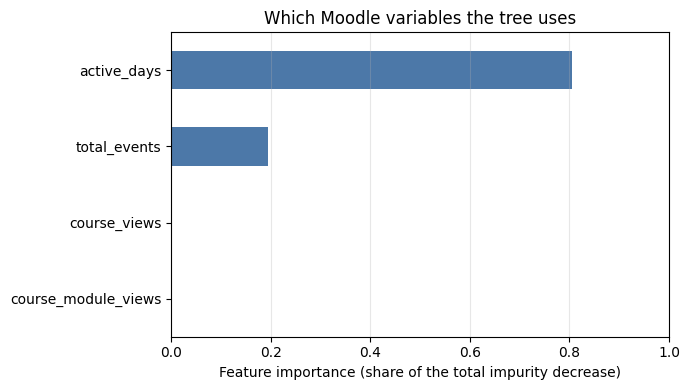

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))

importance.sort_values().plot.barh(ax=ax, color="#4c78a8")
ax.set_xlabel("Feature importance (share of the total impurity decrease)")
ax.set_title("Which Moodle variables the tree uses")
ax.set_xlim(0, 1)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig("decision_tree_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Why the test years are difficult

The tree learns thresholds from the training years. If student activity changes over time, the same threshold means something different in a later year. The table below shows that activity in 2025 and 2026 is much lower than in most training years.

In [12]:
all_years = pd.concat([train, test], ignore_index=True)
all_years.groupby("year")[["total_events", "active_days", "course_module_views", "course_views"]].mean().round(1)

,total_events,active_days,course_module_views,course_views
year,,,,
2019,176.9,21.1,35.1,56.2
2021,297.2,24.2,71.7,74.9
2022,246.8,21.3,60.0,62.3
2023,295.4,22.9,70.9,78.5
2024,351.8,23.6,77.4,69.8
2025,164.2,20.2,50.5,50.5
2026,138.0,18.6,45.2,39.3


## 10. Explanation

**How accurately does the model predict?** The selected tree has `max_depth = 2`, so it makes only two splits and ends up with four leaves. On the validation years inside the training data its MAE is about 18.65 grade points, against 17.11 on the data it was trained on. On the two test years the MAE is **19.65** for 2025 and **21.64** for 2026. The baseline that always predicts the mean training grade (66.93) has an MAE of 20.21 and 21.02. The tree is therefore 0.56 points better than the baseline in 2025 but 0.62 points worse in 2026. RMSE is about 25 grade points in both years and R² is only 0.05 and 0.13, so the tree explains very little of the variation in the final grades.

**Does the tree overfit?** An unrestricted tree overfits badly: its training MAE falls to 0.00 while its cross-validated MAE rises to 25.07. Limiting the depth is therefore necessary, and the validation curve in Section 3 shows that a single split is already worse (19.16), that depth 2 is the best compromise (18.65), and that every additional level after that makes the validation error worse (19.17 at depth 3, 25.07 when unlimited). Even the chosen depth of 2 has a small optimistic gap (17.11 versus 18.65). So the tree does not overfit in its final form, but only because it is kept extremely small; the overfitting risk of a single tree is high.

**What the tree learned.** Only two variables are used: `active_days` (importance 0.81) and `total_events` (0.19); `course_module_views` and `course_views` are not used at all. The rules are readable: a student active on at most 17.5 days with at most 88 events gets 36.5; the same low activity but more events gets 57.7; 18–22.5 active days gives 66.5; more than 22.5 active days gives 76.4. The tree thus rewards regular, spread-out activity, which is plausible.

**Why 2026 is worse than the baseline.** Activity dropped sharply in the test years: the average number of active days is 20.2 in 2025 and 18.6 in 2026, compared with 21.1–24.2 in the training years, and the average number of total events is 164 and 138, against 177–352 in the training years. Most 2026 students therefore fall into the two low-activity leaves and are predicted at 36.5 or 57.7, while their real grades are on average 70.4. The scatter plot shows this as a cloud of 2026 points below the red line: many students with real grades around 70–90 receive predictions of 36.5 or 57.7. The tree cannot extrapolate beyond the leaf averages it has seen, and a threshold learned on earlier, more active cohorts does not transfer to a less active cohort. This is a distribution shift, not a bug in the code.

**Limitations.**
- The model is piecewise constant: it can only output four values (36.5, 57.7, 66.5, 76.4), so it cannot rank students inside a leaf and cannot follow the real grades, which range from 0 to 110.
- A single tree is unstable: a small change in the training data can change the splits completely. A random forest (the next task in the team) averages many trees and is usually more robust.
- Only four simple activity counts from the first 8 weeks are used. Attendance, prior knowledge, homework quality and the exam performance itself are not in the data, and they matter for the final grade.
- Activity is correlated with the grade partly because active students tend to be stronger students; the tree describes an association, not a causal effect.
- 2019 was graded differently from the other years, which adds noise to the training data, and 2020 has no grades at all.
- The test years are small (137 and 142 students), so a few unusual students can move the MAE noticeably.
- The thresholds are learned from years with much higher Moodle activity, which is exactly what makes 2026 predictions too low.

**Conclusion.** The depth-limited tree is interpretable and slightly better than the baseline in 2025, but it does not generalise reliably to 2026. Its main weakness is that it reduces a continuous problem to four average values and depends on activity thresholds that shift between cohorts.